In [ ]:
%pip install pandas
%pip install sodapy


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
from sodapy import Socrata

# Unauthenticated client only works with public data sets. Note 'None'
# in place of application token, and no username or password:
#client = Socrata("data.transportation.gov", None)

client = Socrata( "data.transportation.gov",
                     '1hCte9vYL7IpE7pFTGR1cbn8y',
                     username="hugo.baca4515@coyote.csusb.edu",
                     password="Hugobacaalex1!" )

# First 2000 results, returned as JSON from API / converted to Python list of
# dictionaries by sodapy.
results = client.get_all("7wn6-i5b9")

# Convert to pandas DataFrame
Raw_2023 = pd.DataFrame.from_records(results)
#let's see what we get back
print(Raw_2023)


       railroadcode                        railroadname  year incidentnumber  \
0                UP      Union Pacific Railroad Company  2009      0809LV010   
1                UP      Union Pacific Railroad Company  2009      0809PR005   
2                UP      Union Pacific Railroad Company  2009      0809RS016   
3                UP      Union Pacific Railroad Company  2009      0809SA011   
4                UP      Union Pacific Railroad Company  2009      0809SL005   
...             ...                                 ...   ...            ...   
244704         CRSH       Consolidated Rail Corporation  2016         123182   
244705         CRSH       Consolidated Rail Corporation  2016         123328   
244706         NJTR  New Jersey Transit Rail Operations  2018      201802077   
244707         NJTR  New Jersey Transit Rail Operations  2018      201807361   
244708         NJTR  New Jersey Transit Rail Operations  2018      201807366   

       incidentyear incidentmonth maint

In [6]:
from numpy.core.fromnumeric import sort

column_headers = list(Raw_2023.columns.values)

column_headers.sort()

print("The Column Headers:")
for header in column_headers:
  print(header)

The Column Headers:
ampm
cityname
countycode
countyname
crossingilluminated
crossingusersinjured
crossinguserskilled
crossingwarning
crossingwarningcode
crossingwarningexpanded1
crossingwarningexpanded2
crossingwarningexpanded3
crossingwarningexpanded4
crossingwarningexpanded5
crossingwarningexpanded6
crossingwarningexpanded7
crossingwarningexpanded8
crossingwarningexpandedcode1
crossingwarningexpandedcode2
crossingwarningexpandedcode3
crossingwarningexpandedcode4
crossingwarningexpandedcode5
crossingwarningexpandedcode6
crossingwarningexpandedcode7
crossingwarningexpandedcode8
crossingwarningexplanation
crossingwarningexplanationcode
crossingwarninglocation
crossingwarninglocationcode
date
day
district
division
drivercondition
driverconditioncode
driverinvehicle
driverpassedvehicle
employeesinjured
employeeskilled
equipmentinvolved
equipmentinvolvedcode
equipmentstruck
equipmentstruckcode
equipmenttype
equipmenttypecode
estimatedrecordedspeedcode
estimatedvehiclespeed
form54filed
grad

In [7]:
from numpy import NaN
dictionary_data_raw = pd.read_excel('../Data_Dictionaries/Form_54_Data_Dictionary.xlsx')

dictionary = pd.DataFrame.from_records(dictionary_data_raw)

dictionary.columns.values

dictionary = dictionary.filter(items=['Display Name', 'Description'])

print(dictionary)

                Display Name  \
0    Reporting Railroad Code   
1    Reporting Railroad Name   
2                       Year   
3            Accident Number   
4                   PDF Link   
..                       ...   
168                      NaN   
169                      NaN   
170                      NaN   
171                      NaN   
172                      NaN   

                                           Description  
0    Code of the reporting railroad [Block #1a on F...  
1    Name of the reporting railroad [Block #1 on Fo...  
2                                         Report year   
3    Assigned accident number for the reporting rai...  
4                                     PDF link to form  
..                                                 ...  
168                                                NaN  
169                                                NaN  
170                                                NaN  
171                                          

In [8]:
# Create a dictionary to store the corresponding names and descriptions
name_to_description = {}
for index, row in dictionary.iterrows():
    name_to_description[row['Display Name']] = row['Description']

# Get the description for the variable 'report year'
description = name_to_description['Year']
print(description)

#Personal Prefence: Allows me to quickly pull descriptions for variable.

Report year 


In [9]:
#i would like to break up data into smaller chunks to make it easier to work with
# such as by 10 years

print(Raw_2023['year'].max())
print(Raw_2023['year'].min())




2023
1975


In [10]:
#assuming data collection gets better as time ages, 2023 > 2022 > ...
#so we will use 2023 as the last year of data collection
Raw_2023 = Raw_2023[Raw_2023['year'] == '2023']
print(Raw_2023.head())

from tabulate import tabulate
print(tabulate(Raw_2023, headers = 'keys', tablefmt = 'psql'))


      railroadcode                    railroadname  year incidentnumber  \
2529           CSX              CSX Transportation  2023      000211692   
2530          CFRC   Central Florida Rail Corridor  2023          23132   
15747           UP  Union Pacific Railroad Company  2023      0723LA001   
15748         BNSF            BNSF Railway Company  2023      SW0723201   
15749         BNSF            BNSF Railway Company  2023      SW0723203   

      incidentyear incidentmonth maintenancerailroadcode  \
2529            23            06                     CSX   
2530            23            05                    CFRC   
15747           23            07                      UP   
15748           23            07                    BNSF   
15749           23            07                    BNSF   

              maintenancerailroadname maintainenanceincidentnumber  \
2529               CSX Transportation                    000211692   
2530    Central Florida Rail Corridor           

In [11]:
#Explore for NA's, missing data, and redunnacy

isnaValues = Raw_2023.isna()
print(isnaValues)

# Check for NA values
missing_values = Raw_2023.isna().sum()

#check for null values
missing_data = Raw_2023.isnull().sum()
print(missing_data)

# Check for missing data
for column in Raw_2023.columns:
    if missing_values[column] > 0:
        print(f"The column {column} has {missing_values[column]} missing values.")

# Check for redundancy
for column in Raw_2023.columns:
    if Raw_2023[column].duplicated().sum() > 0:
        print(f"The column {column} has {Raw_2023[column].duplicated().sum()} duplicate values.")

#lets try to clean up raw data

# Calculate the percentage of missing values in each column
missing_values = Raw_2023.isna().mean()

# Drop columns with more than 30% missing values
drop_list = [column for column in missing_values.index if missing_values[column] > 0.3]

# Drop the columns
Raw_2023_clean = Raw_2023.drop(columns=drop_list)


# Check the shape of the raw data
print(f"The Raw Data Frame has {Raw_2023.shape[0]} rows and {Raw_2023.shape[1]} columns.")

print(f"\n The Raw Data Frame has {len(Raw_2023.columns)} labels.")
print(f"\n The Clean Data Frame now has {len(Raw_2023_clean.columns)} labels.")
print("\n Count of labels dropped: \n", len(Raw_2023.columns) - len(Raw_2023_clean.columns) )
print("\n Deleted Labels: \n", drop_list)
print("\n Cleaned Data Labels: \n", Raw_2023_clean.columns.values)

        railroadcode  railroadname   year  incidentnumber  incidentyear  \
2529           False         False  False           False         False   
2530           False         False  False           False         False   
15747          False         False  False           False         False   
15748          False         False  False           False         False   
15749          False         False  False           False         False   
...              ...           ...    ...             ...           ...   
233844         False         False  False           False         False   
233845         False         False  False           False         False   
233846         False         False  False           False         False   
233847         False         False  False           False         False   
233848         False         False  False           False         False   

        incidentmonth  maintenancerailroadcode  maintenancerailroadname  \
2529            False   

In [12]:
from tabulate import tabulate
print(tabulate(Raw_2023_clean, headers = 'keys', tablefmt = 'psql'))

print(Raw_2023_clean.info())

+--------+----------------+----------------------------------------------------------+--------+------------------+----------------+-----------------+---------------------------+----------------------------------------------------------+--------------------------------+---------------------------+----------------------------+-------------------+-------------------------+---------+-------+--------+----------+--------+----------+----------------------+--------------+---------------------+-------------+----------------+----------------------+---------------------+-----------------+-------------------+---------------------+-------------------------+------------------------+--------------------+---------------------------+--------------------------------+-------------------------+------------------------+---------------------------+-----------------------+---------------------------------------+-------------------------+---------------------+------------------------+--------------------+----

COOK                27
HARRIS              22
LOS ANGELES         17
BROWARD             16
PALM BEACH          14
FULTON              14
JEFFERSON           14
SHELBY              13
MARION              12
WAYNE               11
MONTGOMERY          11
JACKSON             10
POLK                 9
ALLEN                9
MARICOPA             9
SUFFOLK              8
EAST BATON ROUGE     8
SAN BERNARDINO       8
ESSEX                8
BUTLER               8
Name: countyname, dtype: int64


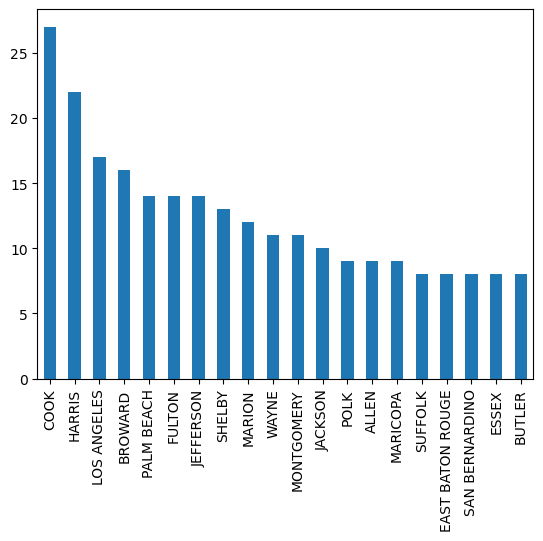

In [18]:
#lets see which county experiences the most accidents
# so basically get a graph x = county, y = number of accidents, all rows in this set are accidents
#get indivial counties and keep track of how many times they appear
import matplotlib.pyplot as plt
incidentsbycounties = Raw_2023_clean['countyname'].value_counts()
#get the top 10 counties
incidentsbycounties = incidentsbycounties[:20,]
print(incidentsbycounties)
incidentsbycounties.plot.bar()
plt.show()


But just becuase accidnets occur, does that mean fatalities occur? 
Does an increase in accidents imply anything about grade?

we have another data set for non-grade crossing data, could we compare and contrast these counties? 
I think so. 

In [15]:
print(Raw_2023_clean.info())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1170 entries, 2529 to 233848
Columns: 115 entries, railroadcode to videoused
dtypes: object(115)
memory usage: 1.0+ MB
None


What about fatalities
Lets find countnies where incidents included fatalities 

quantity of unique counties: 520
+-----+---------------------+---------------------+
|     | countyname          |   totalkilledform57 |
|-----+---------------------+---------------------|
|   0 | ADA                 |                   1 |
|   1 | ADAIR               |                   1 |
|   2 | ADAMS               |                   1 |
|   3 | ALAMEDA             |                   1 |
|   4 | ALLEGAN             |                   1 |
|   5 | ALLEGHENY           |                   0 |
|   6 | ALLEN               |                   0 |
|   7 | ARKANSAS            |                   0 |
|   8 | AROOSTOOK           |                   0 |
|   9 | ASCENSION           |                   0 |
|  10 | ASHTABULA           |                   0 |
|  11 | ATASCOSA            |                   0 |
|  12 | AUSTIN              |                   0 |
|  13 | BALTIMORE           |                   0 |
|  14 | BALTIMORE CITY      |                   0 |
|  15 | BANNOCK             |  

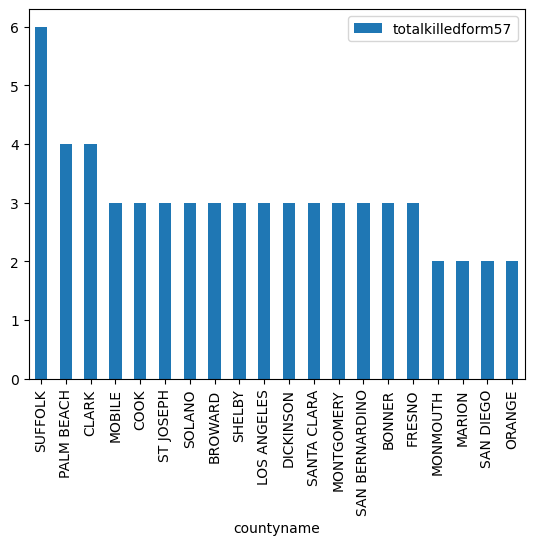

In [77]:
# any county has several entries, and i want the sum of all totalkilledoform57 related to x county in table format: county, totalkilledoform57
#how many counties are there?
county_count = Raw_2023_clean['countyname'].nunique()
print("quantity of unique counties:", county_count)

result_df = Raw_2023_clean.groupby('countyname')['totalkilledform57'].sum().reset_index()
print(tabulate(result_df, headers = 'keys', tablefmt = 'psql'))

# top 10 counties with the most deaths
top20countiesbyfatalities = result_df.sort_values(by=['totalkilledform57'], ascending=False).reset_index()
print(top20countiesbyfatalities.head(20))

#plot top20 counties by fatalities
top20countiesbyfatalities.head(20).plot.bar(x='countyname', y='totalkilledform57')
plt.show()

Theroretical, the crossings with most incidents should be points of intrest
Lets find the top 20 crossings id by incident (frequency)

025422P    4
718062K    3
637728K    3
725759B    3
631785D    3
050330S    3
661926S    2
501740N    2
723692P    2
028442L    2
743727T    2
628146G    2
180024H    2
734735L    2
140356T    2
796331L    2
140833J    2
348506D    2
727088L    2
028639M    2
Name: gradecrossingid, dtype: int64


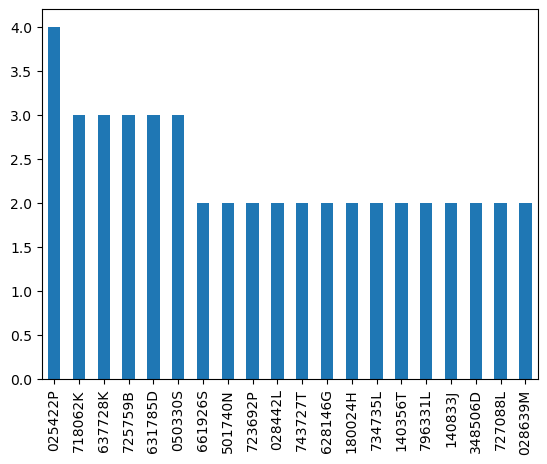

   countyname gradecrossingid  count
0         ADA         819330X      2
1         ADA         819326H      1
2       ADAIR         330391G      1
3       ADAIR         330625H      1
4       ADAMS         070779Y      1
5       ADAMS         072813K      1
6       ADAMS         083178C      1
7       ADAMS         804419H      1
8     ALAMEDA         749712Y      2
9     ALAMEDA         749634U      1
10    ALAMEDA         749728V      1
11    ALAMEDA         749774W      1
12    ALAMEDA         751154H      1
13    ALAMEDA         834232U      1
14    ALLEGAN         234677M      1
15    ALLEGAN         234707C      1
16  ALLEGHENY         507692W      1
17      ALLEN         155680C      1
18      ALLEN         447767B      1
19      ALLEN         478025T      1


In [122]:
GCF = Raw_2023_clean['gradecrossingid'].value_counts()
print(GCF.head(20))

GCF = GCF[:20,]
GCF.plot.bar(x='index', y='count')
plt.show()

GCFbycounty = Raw_2023_clean.groupby('countyname')['gradecrossingid'].value_counts().reset_index(name='count')
print(GCFbycounty.head(20))



In [102]:
topcorssingid = Raw_2023_clean[Raw_2023_clean['gradecrossingid'] == '025422P'].get(['countyname', 'statename'])
print(topcorssingid)


      countyname statename
15748   MARICOPA   ARIZONA
15749   MARICOPA   ARIZONA
15756   MARICOPA   ARIZONA
15763   MARICOPA   ARIZONA


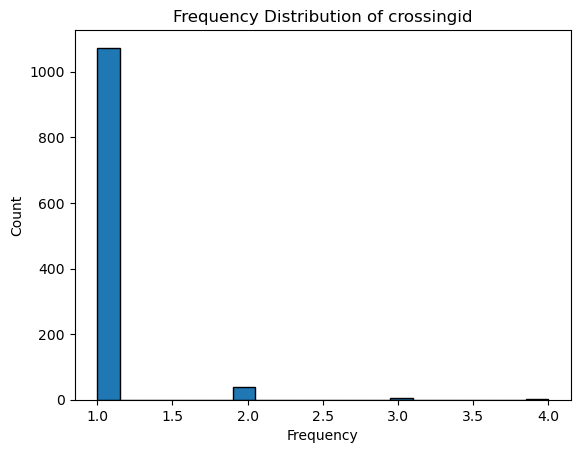

In [124]:
# Assuming you have a DataFrame named df with a 'crossingid' column
# Use value_counts() to get the frequency of each unique crossingid
crossingid_frequency = Raw_2023_clean['gradecrossingid'].value_counts()

# Plot a histogram of the frequencies
plt.hist(crossingid_frequency, bins=20, edgecolor='k')
plt.xlabel('Frequency')
plt.ylabel('Count')
plt.title('Frequency Distribution of crossingid')
plt.show()

/var/folders/8s/cfwx8yqs1h7921qxk7ssn8sm0000gn/T/ipykernel_19782/2178112647.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(crossingid_frequency, kde=True)


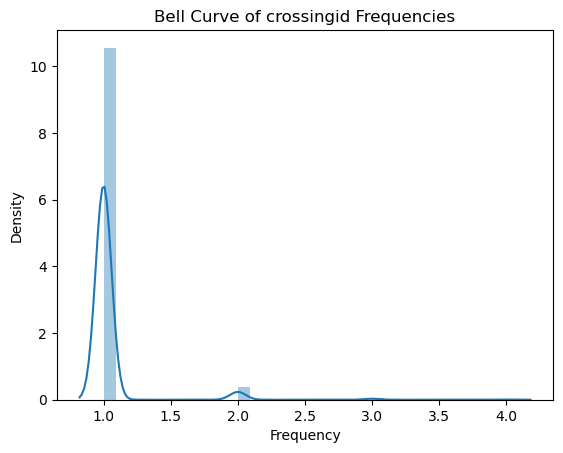

In [126]:
import seaborn as sns

# Assuming you have a DataFrame named df with a 'crossingid' column
# Use value_counts() to get the frequency of each unique crossingid
crossingid_frequency = Raw_2023_clean['gradecrossingid'].value_counts()

# Create a bell curve (normal distribution) plot
sns.distplot(crossingid_frequency, kde=True)
plt.xlabel('Frequency')
plt.ylabel('Density')
plt.title('Bell Curve of crossingid Frequencies')
plt.show()